##  Step 1: NLP Fundamentals, Text Preprocessing & RegEx


### 1.1  Theory Notes (Markdown cells)


#### 1. What is NLP? Why do businesses need it? Name 3 real applications.

**What is NLP?**

NLP (Natural Language Processing) is a branch of Artificial Intelligence (AI) that helps computers understand, interpret, process and generate human languages like English, Hindi and Gujarati.

**Why do businesses need NLP?**

1. It helps understand customer feedback and reviews.
2. It automatically analyses thousands of customer messages.
3. It saves time and reduces manual work.
4. It helps businesses make better decisions.
5. It improves customer service and satisfaction.

**3 Real-Life Applications of NLP**

**1. Voice Assistants:** Google Assistant and Siri understand voice commands and respond to questions.

**2. Spam Email Detection:** Gmail uses NLP techniques to identify spam messages and separate them from important emails.

**3. Language Translation:** Google Translate translates languages like English, Hindi and Gujarati into other languages.

---

#### 2. List 4 Challenges in NLP with One Example Each.

NLP faces many challenges because human language is complex and people communicate in different ways.

#### 1. Ambiguity
**Meaning:** One word or sentence can have multiple meanings depending on the context.

**Example:** "I saw a bat near the airport."

Here, bat can mean a cricket bat or an animal.

#### 2. Sarcasm
**Meaning:** People sometimes say something positive but actually mean something negative.

**Example:** "Great! My flight is delayed by 5 hours. Amazing service!"

Here, the passenger is unhappy but uses positive words like Great and Amazing.

#### 3. Slang and Spelling Mistakes
**Meaning:** People use short forms, informal words and incorrect spellings in social media messages.

**Example:** "Flite is sooo late yaar, worst servce!"

Here, Flite means Flight and servce means Service.

#### 4. Hinglish Code-Mixing
**Meaning:** People mix two or more languages in one sentence.

**Example:** "Flight bahut late hai, airline ki service bakwaas hai."

Here, Hindi and English words are mixed together.

---

##### 3. Stages of a Basic NLP Pipeline from Raw Text to Final Prediction.

NLP Pipeline is a sequence of steps that converts raw text into meaningful predictions.


1. **Raw Text:** Collect original text from tweets, reviews or customer messages.

   Example: "My flight is very late!"

2. **Text Cleaning:** Remove URLs, mentions, special characters and unnecessary symbols.

   Example: "My flight is very late"

3. **Tokenization:** Split the sentence into individual words.

   Example: ["My", "flight", "is", "very", "late"]

4. **Stop Word Removal:** Remove common unnecessary words while keeping important sentiment words.

   Example: ["flight", "late"]

5. **Lemmatization:** Convert words into their meaningful root form.

   Example: "delayed" → "delay"

6. **Feature Extraction:** Convert text into numerical values using Bag-of-Words (BoW) or TF-IDF.

   Example: Text → [0.2, 0.5, 0.8]

7. **Model Prediction:** Machine Learning model analyses numerical features and predicts sentiment.

8. **Final Prediction:** The model classifies the tweet into one of three categories:
   - Negative
   - Neutral
   - Positive

**Example Final Output:**

Input Tweet: "My flight is very late!"

Predicted Sentiment: **Negative**


### 1.2  Load & Explore


In [25]:
import os

print(os.getcwd())
print(os.listdir())

c:\AI - ML DS\AI - ML Ds\NLP\Project\Practical_exam\Notebook
['Prectical-exam.ipynb']


In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\AI - ML DS\AI - ML Ds\NLP\Project\Practical_exam\Tweets.csv")

df = df[['airline', 'airline_sentiment', 'negativereason', 'text']]

print("Shape:", df.shape)
print(df.head(5))
print("\nSentiment Count:")
print(df['airline_sentiment'].value_counts())

Shape: (14640, 4)
          airline airline_sentiment negativereason  \
0  Virgin America           neutral            NaN   
1  Virgin America          positive            NaN   
2  Virgin America           neutral            NaN   
3  Virgin America          negative     Bad Flight   
4  Virgin America          negative     Can't Tell   

                                                text  
0                @VirginAmerica What @dhepburn said.  
1  @VirginAmerica plus you've added commercials t...  
2  @VirginAmerica I didn't today... Must mean I n...  
3  @VirginAmerica it's really aggressive to blast...  
4  @VirginAmerica and it's a really big bad thing...  

Sentiment Count:
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64


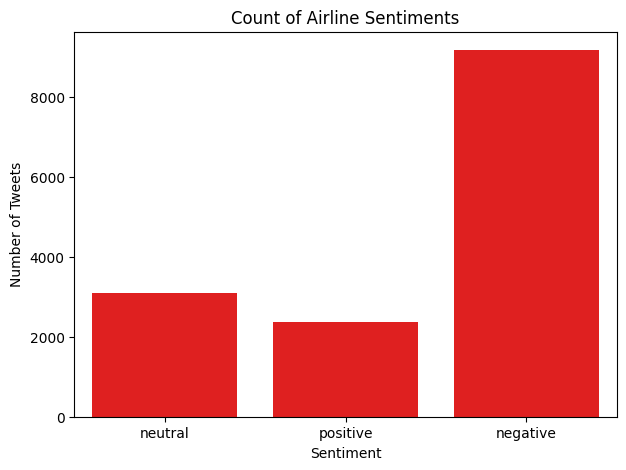

In [27]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='airline_sentiment', color='red')

plt.title("Count of Airline Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.show()


In [28]:
negative = (df['airline_sentiment'] == 'negative').sum()
total = len(df)

negative_percentage = (negative / total) * 100

print("Negative Tweets:", negative)
print("Total Tweets:", total)
print("Negative Percentage:", round(negative_percentage, 2), "%")

Negative Tweets: 9178
Total Tweets: 14640
Negative Percentage: 62.69 %


The negative tweets percentage shows customer dissatisfaction, and class imbalance may affect the performance of the machine learning model.

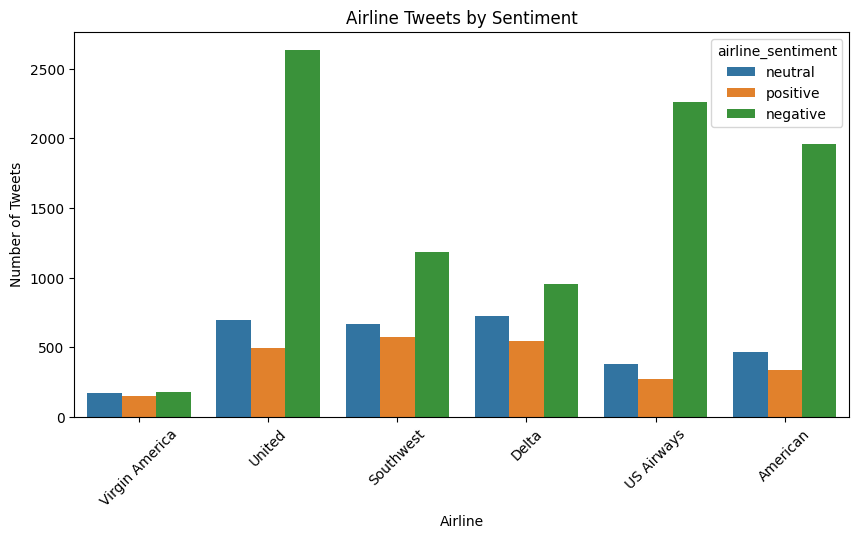

In [29]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='airline', hue='airline_sentiment')

plt.title("Airline Tweets by Sentiment")
plt.xlabel("Airline")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=45)
plt.show()

In [30]:
negative_share = pd.crosstab(
    df['airline'],
    df['airline_sentiment'],
    normalize='index'
) * 100

print(negative_share.round(2))

highest_airline = negative_share['negative'].idxmax()
highest_share = negative_share['negative'].max()

print("\nAirline with Highest Negative Share:", highest_airline)
print("Negative Share:", round(highest_share, 2), "%")

airline_sentiment  negative  neutral  positive
airline                                       
American              71.04    16.78     12.18
Delta                 42.98    32.54     24.48
Southwest             49.01    27.44     23.55
US Airways            77.69    13.08      9.23
United                68.89    18.24     12.87
Virgin America        35.91    33.93     30.16

Airline with Highest Negative Share: US Airways
Negative Share: 77.69 %


In [31]:
df['tweet_length'] = df['text'].apply(lambda x: len(str(x).split()))

print(df[['text', 'tweet_length']].head(5))

                                                text  tweet_length
0                @VirginAmerica What @dhepburn said.             4
1  @VirginAmerica plus you've added commercials t...             9
2  @VirginAmerica I didn't today... Must mean I n...            12
3  @VirginAmerica it's really aggressive to blast...            17
4  @VirginAmerica and it's a really big bad thing...            10


airline_sentiment
negative    19.69
neutral     14.41
positive    14.01
Name: tweet_length, dtype: float64


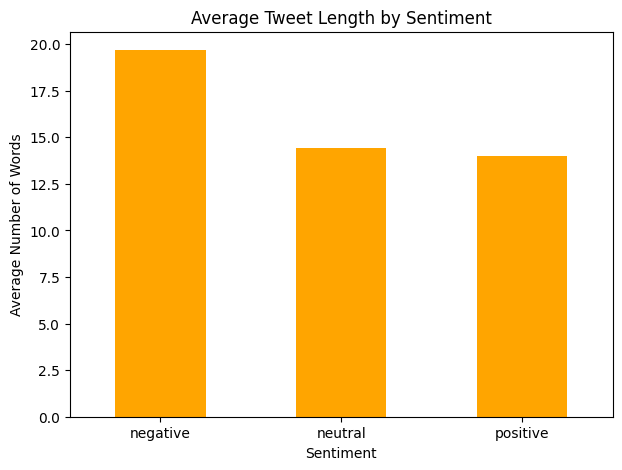

In [32]:
avg_length = df.groupby('airline_sentiment')['tweet_length'].mean()

print(avg_length.round(2))

plt.figure(figsize=(7, 5))
avg_length.plot(kind='bar', color='orange')

plt.title("Average Tweet Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average Number of Words")
plt.xticks(rotation=0)
plt.show()

Average tweet length helps identify whether negative, neutral or positive tweets contain more words.

### 1.3  Regular Expressions (RegEx)


In [33]:
import re
from collections import Counter

mentions = []

for txt in df['text']:
    mentions.extend(re.findall(r'@\w+', str(txt)))

top_mentions = Counter(mentions).most_common(5)

print("Top 5 Most Mentioned Handles:")
print(top_mentions)

Top 5 Most Mentioned Handles:
[('@united', 3765), ('@AmericanAir', 2926), ('@USAirways', 2907), ('@SouthwestAir', 2409), ('@JetBlue', 2198)]


The top five mentioned handles identify the most frequently tagged Twitter accounts in airline tweets.

In [34]:
hashtags = []

for txt in df['text']:
    hashtags.extend(re.findall(r'#\w+', str(txt)))

top_hashtags = Counter(hashtags).most_common(5)

print("Top 5 Most Used Hashtags:")
print(top_hashtags)

Top 5 Most Used Hashtags:
[('#DestinationDragons', 75), ('#fail', 57), ('#jetblue', 35), ('#UnitedAirlines', 35), ('#customerservice', 34)]


The most used hashtags highlight popular topics and discussions related to airlines.

In [35]:
url_tweets = df[df['text'].str.contains(r'http\S+', regex=True, na=False)]

url_count = len(url_tweets)

negative_count = (url_tweets['airline_sentiment'] == 'negative').sum()

negative_percentage = (negative_count / url_count) * 100 if url_count > 0 else 0

print("Total Tweets Containing URLs:", url_count)
print("Negative Tweets:", negative_count)
print("Negative Percentage:", round(negative_percentage, 2), "%")

Total Tweets Containing URLs: 1173
Negative Tweets: 448
Negative Percentage: 38.19 %


In [36]:
flight_tweets = df[
    df['text'].str.contains(r'(?i)flight\s*#?\d+', regex=True, na=False)
]

print("Total Tweets Mentioning Flight Numbers:", len(flight_tweets))

print("\nThree Examples:")
for txt in flight_tweets['text'].head(3):
    print(txt)
    print()

Total Tweets Mentioning Flight Numbers: 606

Three Examples:
@VirginAmerica help, left expensive headphones on flight 89 IAD to LAX today. Seat 2A. No one answering L&amp;F number at LAX!

@VirginAmerica plz help me win my bid upgrade for my flight 2/27 LAX---&gt;SEA!!!  🍷👍💺✈️

@VirginAmerica Is flight 769 on it's way? Was supposed to take off 30 minutes ago. Website still shows "On Time" not "In Flight". Thanks.



In [37]:
def clean_regex(txt):
    txt = re.sub(r'@\w+', 'USER', str(txt))
    txt = re.sub(r'http\S+', 'LINK', txt)
    return txt

df['replaced_text'] = df['text'].apply(clean_regex)

for i in range(3):
    print("Before:", df['text'].iloc[i])
    print("After: ", df['replaced_text'].iloc[i])
    print("-" * 80)

Before: @VirginAmerica What @dhepburn said.
After:  USER What USER said.
--------------------------------------------------------------------------------
Before: @VirginAmerica plus you've added commercials to the experience... tacky.
After:  USER plus you've added commercials to the experience... tacky.
--------------------------------------------------------------------------------
Before: @VirginAmerica I didn't today... Must mean I need to take another trip!
After:  USER I didn't today... Must mean I need to take another trip!
--------------------------------------------------------------------------------


Replacing mentions and URLs with common tokens standardizes tweet text and makes it easier for further NLP processing.

### 1.4  Text Preprocessing Pipeline



In [38]:
import nltk

packages = [
    'punkt',
    'punkt_tab',
    'stopwords',
    'wordnet',
    'averaged_perceptron_tagger',
    'averaged_perceptron_tagger_eng'
]

for p in packages:
    try:
        nltk.data.find({
            'punkt': 'tokenizers/punkt',
            'punkt_tab': 'tokenizers/punkt_tab',
            'stopwords': 'corpora/stopwords',
            'wordnet': 'corpora/wordnet',
            'averaged_perceptron_tagger': 'taggers/averaged_perceptron_tagger',
            'averaged_perceptron_tagger_eng': 'taggers/averaged_perceptron_tagger_eng'
        }[p])

        print(p, "Downloaded")

    except LookupError:
        print(p, "Not Downloaded")

punkt Downloaded
punkt_tab Downloaded
stopwords Downloaded
wordnet Not Downloaded
averaged_perceptron_tagger Downloaded
averaged_perceptron_tagger_eng Downloaded


Why Do We Keep Negation Words?

Stop words are common words that are often removed during text preprocessing.

However, we keep the words **not, no and nor** because they carry important sentiment information.

Example:
- "The flight is good" → Positive sentiment.
- "The flight is not good" → Negative sentiment.

If we remove the word "not", the meaning of the sentence changes.
Therefore, we keep negation words to preserve the correct sentiment.

In [39]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words('english'))
stop_words = stop_words - {'not', 'no', 'nor'}
lemmatizer = WordNetLemmatizer()

def clean_text(text):

    text = str(text).lower()

    # Remove mentions
    text = re.sub(r'@\w+', '', text)

    # Remove URLs
    text = re.sub(r'http\S+', '', text)

    # Remove # symbol but keep hashtag word
    text = re.sub(r'#', '', text)

    # Remove special characters and numbers
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)

    # Tokenization
    tokens = word_tokenize(text)

    # Remove stopwords
    tokens = [word for word in tokens if word not in stop_words]

    # Lemmatization
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    # Join tokens
    return ' '.join(tokens)

In [40]:
df['clean_text'] = df['text'].apply(clean_text)

print(df[['text', 'clean_text']].head(5))

                                                text  \
0                @VirginAmerica What @dhepburn said.   
1  @VirginAmerica plus you've added commercials t...   
2  @VirginAmerica I didn't today... Must mean I n...   
3  @VirginAmerica it's really aggressive to blast...   
4  @VirginAmerica and it's a really big bad thing...   

                                          clean_text  
0                                               said  
1             plus added commercial experience tacky  
2             today must mean need take another trip  
3  really aggressive blast obnoxious entertainmen...  
4                               really big bad thing  


In [41]:
for i in range(5):

    print("Original Text:")
    print(df['text'].iloc[i])

    print("\nCleaned Text:")
    print(df['clean_text'].iloc[i])

    print("-" * 80)

Original Text:
@VirginAmerica What @dhepburn said.

Cleaned Text:
said
--------------------------------------------------------------------------------
Original Text:
@VirginAmerica plus you've added commercials to the experience... tacky.

Cleaned Text:
plus added commercial experience tacky
--------------------------------------------------------------------------------
Original Text:
@VirginAmerica I didn't today... Must mean I need to take another trip!

Cleaned Text:
today must mean need take another trip
--------------------------------------------------------------------------------
Original Text:
@VirginAmerica it's really aggressive to blast obnoxious "entertainment" in your guests' faces &amp; they have little recourse

Cleaned Text:
really aggressive blast obnoxious entertainment guest face amp little recourse
--------------------------------------------------------------------------------
Original Text:
@VirginAmerica and it's a really big bad thing about it

Cleaned Text:


Text preprocessing removes unnecessary words and symbols while preserving important sentiment information, making tweets suitable for NLP analysis.

### 1.5  Stemming vs Lemmatization


In [42]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

ps = PorterStemmer()
lemmatizer = WordNetLemmatizer()

In [43]:
words = ['delayed', 'cancelled', 'flying', 'flights',
         'waiting', 'lost', 'bags', 'thanks']

result = []

for word in words:
    stem = ps.stem(word)
    lemma = lemmatizer.lemmatize(word)

    result.append([word, stem, lemma])

df_result = pd.DataFrame(
    result,
    columns=['Original Word', 'Porter Stem', 'WordNet Lemma']
)

print(df_result)

  Original Word Porter Stem WordNet Lemma
0       delayed       delay       delayed
1     cancelled      cancel     cancelled
2        flying         fli        flying
3       flights      flight        flight
4       waiting        wait       waiting
5          lost        lost          lost
6          bags         bag           bag
7        thanks       thank        thanks


Stemming cuts words to their root form, while lemmatization converts words into meaningful dictionary forms.

**Difference Between Stemming and Lemmatization**

**1. Stemming:**
- Stemming removes prefixes or suffixes from words.
- It may produce words that are not meaningful dictionary words.
- It is faster and simpler.

Example:
- Flying → fli
- Waiting → wait

**2. Lemmatization:**
- Lemmatization converts words into their meaningful dictionary base form.
- It produces meaningful words.
- It is slower but more accurate.

Example:
- Flights → flight
- Bags → bag

**Which One Should We Choose?**

- **Quick Prototype:** Stemming, because it is faster and requires less processing time.
- **Polished Project:** Lemmatization, because it produces meaningful words and better preserves language meaning.


### 1.6  Word Frequency


In [44]:
from collections import Counter

In [45]:
negative_text = df[df['airline_sentiment'] == 'negative']['clean_text']
negative_words = ' '.join(negative_text).split()
negative_freq = Counter(negative_words)
top_negative = negative_freq.most_common(15)

print("Top 15 Negative Words:")
print(top_negative)

Top 15 Negative Words:
[('flight', 3378), ('not', 1401), ('no', 1327), ('hour', 1116), ('get', 1017), ('cancelled', 926), ('customer', 783), ('service', 772), ('u', 762), ('time', 749), ('bag', 664), ('help', 622), ('hold', 616), ('plane', 601), ('call', 511)]


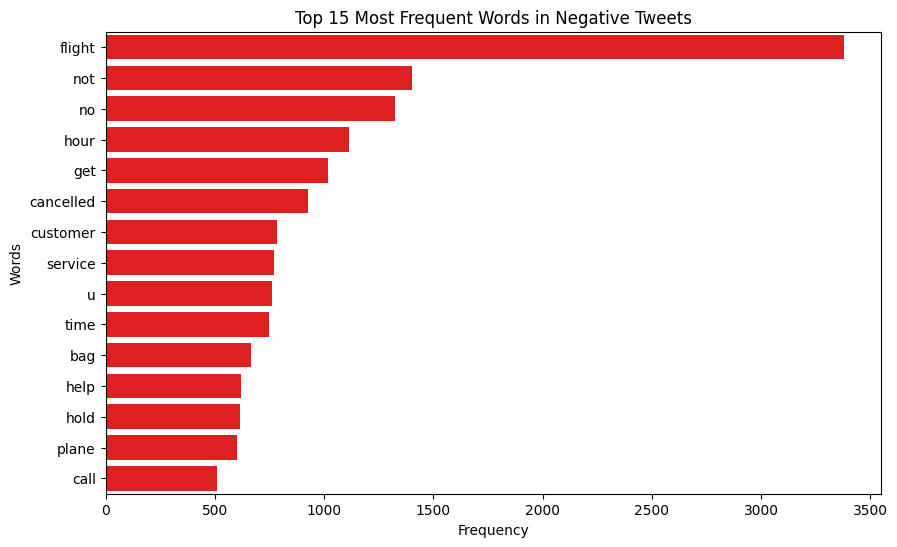

In [46]:
neg_words = pd.DataFrame(top_negative, columns=['Word', 'Frequency'])

plt.figure(figsize=(10, 6))

sns.barplot(data=neg_words, x='Frequency', y='Word', color='red')
plt.title("Top 15 Most Frequent Words in Negative Tweets")
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.show()

In [47]:
positive_text = df[df['airline_sentiment'] == 'positive']['clean_text']
positive_words = ' '.join(positive_text).split()
positive_freq = Counter(positive_words)
top_positive = positive_freq.most_common(15)

print("Top 15 Positive Words:")
print(top_positive)

Top 15 Positive Words:
[('thanks', 611), ('thank', 455), ('flight', 442), ('great', 236), ('service', 164), ('u', 137), ('love', 136), ('customer', 124), ('guy', 123), ('get', 120), ('good', 110), ('time', 109), ('much', 109), ('airline', 107), ('best', 105)]


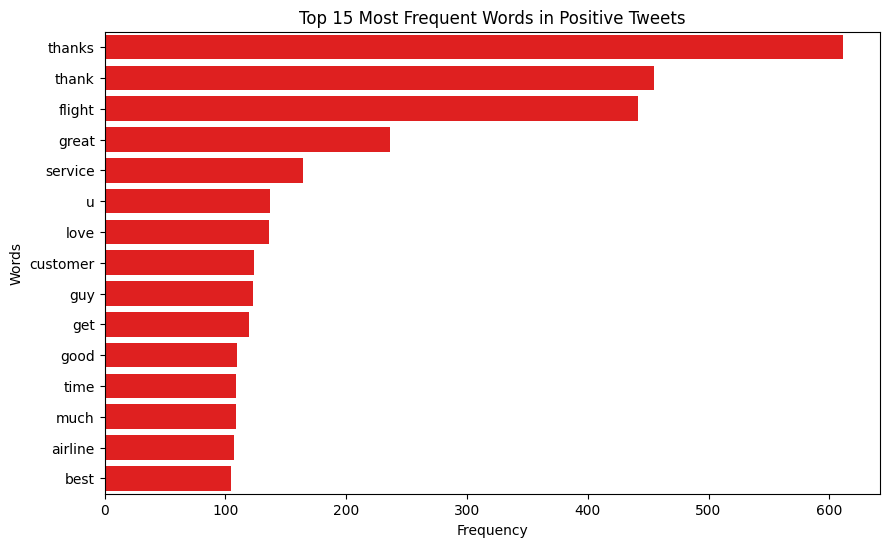

In [48]:
pos_words = pd.DataFrame(top_positive, columns=['Word', 'Frequency'])

plt.figure(figsize=(10, 6))

sns.barplot(data=pos_words, x='Frequency', y='Word', color='red')
plt.title("Top 15 Most Frequent Words in Positive Tweets")
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.show()

Positive tweets frequently contain words related to thanks, appreciation and good customer experiences.

##### Word Frequency Analysis

Negative tweets commonly contain words related to delays, cancellations, problems and poor service, while positive tweets contain words related to thanks, appreciation and good experiences.

Some words may appear in both lists, such as airline, flight and customer. These common words are less useful for distinguishing sentiment because they appear in both positive and negative tweets.

Therefore, words that are more specific to each sentiment can be useful features for sentiment classification.

## Step 2: Feature Extraction — Bag-of-Words, TF-IDF & N-Grams


### 2.1  Bag-of-Words (BoW) on the Tiny Corpus


In [49]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

In [50]:
documents = [
    "flight was on time",
    "flight was late",
    "great crew and great service",
    "not happy with the service"
]

print(documents)

['flight was on time', 'flight was late', 'great crew and great service', 'not happy with the service']


In [51]:
cv = CountVectorizer()

x = cv.fit_transform(documents)

In [52]:
print("Vocabulary:")
print(cv.get_feature_names_out())

Vocabulary:
['and' 'crew' 'flight' 'great' 'happy' 'late' 'not' 'on' 'service' 'the'
 'time' 'was' 'with']


In [53]:
bow_df = pd.DataFrame(
    x.toarray(),
    columns=cv.get_feature_names_out(),
    index=['Doc 1', 'Doc 2', 'Doc 3', 'Doc 4']
)

print(bow_df)

       and  crew  flight  great  happy  late  not  on  service  the  time  \
Doc 1    0     0       1      0      0     0    0   1        0    0     1   
Doc 2    0     0       1      0      0     1    0   0        0    0     0   
Doc 3    1     1       0      2      0     0    0   0        1    0     0   
Doc 4    0     0       0      0      1     0    1   0        1    1     0   

       was  with  
Doc 1    1     0  
Doc 2    1     0  
Doc 3    0     0  
Doc 4    0     1  


The matrix represents each document using numerical word frequencies, where 0 means absent and positive values show word counts.


**Understanding the Bag-of-Words Matrix**

**1. What does each number in the matrix mean?**

Each number represents the frequency of a word in a document.
- 0 means the word is not present.
- 1 means the word appears once.
- 2 means the word appears twice.

**2. Doc 3 contains the word "great" twice. Where do you see that?**

In Doc 3, the value under the "great" column is 2 because the sentence is "great crew and great service".

**3. What does Bag-of-Words ignore?**

Bag-of-Words ignores:
- Word order.
- Grammar and sentence structure.
- Context and actual meaning of words.

**Final Interpretation**

Bag-of-Words converts text into numerical word counts. It captures word frequency but ignores word order and context.


### 2.2  TF-IDF on the Tiny Corpus


In [54]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

In [55]:
documents = [
    "flight was on time",
    "flight was late",
    "great crew and great service",
    "not happy with the service"
]

In [56]:
tfidf = TfidfVectorizer()

tfidf_matrix = tfidf.fit_transform(documents)

In [57]:
df_tfidf = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf.get_feature_names_out(),
    index=["Doc 1", "Doc 2", "Doc 3", "Doc 4"]
)

print(df_tfidf.round(2))

        and  crew  flight  great  happy  late   not    on  service   the  \
Doc 1  0.00  0.00    0.44   0.00   0.00  0.00  0.00  0.56     0.00  0.00   
Doc 2  0.00  0.00    0.53   0.00   0.00  0.67  0.00  0.00     0.00  0.00   
Doc 3  0.39  0.39    0.00   0.78   0.00  0.00  0.00  0.00     0.31  0.00   
Doc 4  0.00  0.00    0.00   0.00   0.47  0.00  0.47  0.00     0.37  0.47   

       time   was  with  
Doc 1  0.56  0.44  0.00  
Doc 2  0.00  0.53  0.00  
Doc 3  0.00  0.00  0.00  
Doc 4  0.00  0.00  0.47  


In [58]:
words = tfidf.get_feature_names_out()

flight_idf = tfidf.idf_[list(words).index("flight")]
crew_idf = tfidf.idf_[list(words).index("crew")]

print("Flight IDF:", round(flight_idf, 2))
print("Crew IDF:", round(crew_idf, 2))

Flight IDF: 1.51
Crew IDF: 1.92


##### TF (Term Frequency)

TF measures how many times a word appears in a document.

**Formula:**

$$
TF(t,d)=\frac{\text{Word Frequency}}{\text{Total Words}}
$$

##### IDF (Inverse Document Frequency)

IDF measures how important a word is across all documents. Rare words get higher IDF values.

**Formula:**

$$
IDF(t)=\log\left(\frac{N+1}{DF(t)+1}\right)+1
$$

##### TF-IDF (Term Frequency – Inverse Document Frequency)

TF-IDF combines TF and IDF to calculate the importance of a word in a document.

**Formula:**

$$
TFIDF(t,d)=TF(t,d)\times IDF(t)
$$

**Interpretation:** TF-IDF gives higher importance to words that are frequent in a document but rare across all documents.

### 2.3  N-Grams


In [59]:
cv = CountVectorizer(ngram_range=(2, 2))
bigram_matrix = cv.fit_transform(documents)

print(cv.get_feature_names_out())

['and great' 'crew and' 'flight was' 'great crew' 'great service'
 'happy with' 'not happy' 'on time' 'the service' 'was late' 'was on'
 'with the']


In [60]:
cv = CountVectorizer(ngram_range=(1, 2))
ngram_matrix = cv.fit_transform(documents)

print(cv.get_feature_names_out())

['and' 'and great' 'crew' 'crew and' 'flight' 'flight was' 'great'
 'great crew' 'great service' 'happy' 'happy with' 'late' 'not'
 'not happy' 'on' 'on time' 'service' 'the' 'the service' 'time' 'was'
 'was late' 'was on' 'with' 'with the']


##### Bigram Meaning

The bigram **"not happy"** from Doc 4 carries the real meaning of the sentence.

A bigram captures the relationship between two words. The word **"happy"** alone shows a positive meaning, but **"not happy"** expresses a negative meaning.

A BoW model that sees only **"happy"** may interpret the sentence as positive because it ignores the word order and the negation word "not".

### 2.4  Features on Real Tweets


In [61]:
cv = CountVectorizer(max_features=3000)
X_bow = cv.fit_transform(df["clean_text"])

print("Matrix Shape:", X_bow.shape)

sparsity_bow = 100 * (1 - X_bow.count_nonzero() / (X_bow.shape[0] * X_bow.shape[1]))
print("Sparsity:", round(sparsity_bow, 2), "%")

Matrix Shape: (14640, 3000)
Sparsity: 99.74 %


In [62]:
tf = TfidfVectorizer(max_features=3000)
X_tfidf = tf.fit_transform(df["clean_text"])

print("Matrix Shape:", X_tfidf.shape)

avg_tfidf = X_tfidf.mean(axis=0).A1
top_words = pd.Series(avg_tfidf, index=tf.get_feature_names_out())

print(top_words.sort_values(ascending=False).head(10))


Matrix Shape: (14640, 3000)
flight       0.044322
thanks       0.022717
not          0.020999
no           0.019846
get          0.019221
hour         0.017484
thank        0.017176
cancelled    0.015532
service      0.015255
customer     0.014534
dtype: float64


Interpretation: These are the 10 words with the highest average TF-IDF scores across all tweets.

In [63]:
negative_tweets = df[df["airline_sentiment"] == "negative"]["clean_text"]

bigram = CountVectorizer(ngram_range=(2, 2), max_features=3000)
X_bigram = bigram.fit_transform(negative_tweets)

bigram_counts = X_bigram.sum(axis=0).A1
top_bigrams = pd.Series(
    bigram_counts,
    index=bigram.get_feature_names_out()
)

print(top_bigrams.sort_values(ascending=False).head(10))


customer service       457
cancelled flightled    448
late flight            221
flight cancelled       221
cancelled flighted     204
late flightr           145
cancelled flight       140
flight delayed         136
hold hour              128
no one                 126
dtype: int64


Interpretation: The most frequent bigrams help identify common complaints in negative tweets.

In [64]:
sparsity_tfidf = 100 * (1 - X_tfidf.count_nonzero() / (X_tfidf.shape[0] * X_tfidf.shape[1]))

sparsity_bigram = 100 * (1 - X_bigram.count_nonzero() / (X_bigram.shape[0] * X_bigram.shape[1]))

results = pd.DataFrame({
    "Method": ["BoW", "TF-IDF", "Bigram"],
    "Number of features": [
        X_bow.shape[1],
        X_tfidf.shape[1],
        X_bigram.shape[1]
    ],
    "Sparsity %": [
        round(sparsity_bow, 2),
        round(sparsity_tfidf, 2),
        round(sparsity_bigram, 2)
    ]
})

print(results)

   Method  Number of features  Sparsity %
0     BoW                3000       99.74
1  TF-IDF                3000       99.74
2  Bigram                3000       99.92


##### Complaint Themes

The most frequent bigrams reveal common passenger complaints, such as flight delays, cancelled flights, baggage problems, and poor customer service.

These bigrams help identify the main issues passengers are discussing in negative tweets.

##  Step 3: Word Embeddings — Word2Vec (CBoW & Skip-gram)


### 3.1  Prepare Tokens


In [65]:
df['tokens'] = df['clean_text'].apply(lambda x: x.split())

df[['clean_text', 'tokens']].head()

,clean_text,tokens
0,said,[said]
1,plus added commercial experience tacky,"[plus, added, commercial, experience, tacky]"
2,today must mean need take another trip,"[today, must, mean, need, take, another, trip]"
3,really aggressive blast obnoxious entertainmen...,"[really, aggressive, blast, obnoxious, enterta..."
4,really big bad thing,"[really, big, bad, thing]"


Interpretation: Each cleaned tweet is converted into a list of individual words called tokens.

In [66]:
avg_tokens = df['tokens'].apply(len).mean()

print("Average tokens per tweet:", round(avg_tokens, 2))

Average tokens per tweet: 8.88


Interpretation: On average, each tweet contains approximately avg_tokens words.

In [67]:
unique_words = set()

for words in df['tokens']:
    unique_words.update(words)

print("Total unique words:", len(unique_words))

Total unique words: 10135


In [68]:
print("Dataset Shape:", df.shape)
print("Average Tokens:", round(avg_tokens, 2))
print("Unique Words:", len(unique_words))

Dataset Shape: (14640, 8)
Average Tokens: 8.88
Unique Words: 10135


The tweets were successfully tokenized, and the average tokens per tweet and total unique vocabulary were calculated for Word2Vec training.

### 3.2  Train CBoW and Skip-gram Models


In [69]:
from gensim.models import Word2Vec

In [70]:
cbow_model = Word2Vec(
    sentences=documents,
    vector_size=100,
    window=5,
    min_count=3,
    sg=0,
    epochs=15,
    seed=42,
    workers=1
)

Interpretation: The CBoW model learns word vectors by predicting a target word from its surrounding context words.

In [71]:
skipgram_model = Word2Vec(
    sentences=documents,
    vector_size=100,
    window=5,
    min_count=3,
    sg=1,
    epochs=15,
    seed=42,
    workers=1
)

Interpretation: The Skip-gram model learns word vectors by predicting surrounding context words from a target word.

In [72]:
print("CBoW Vocabulary Size:", len(cbow_model.wv))
print("Skip-gram Vocabulary Size:", len(skipgram_model.wv))

CBoW Vocabulary Size: 13
Skip-gram Vocabulary Size: 13


In [73]:
print("flight in CBoW:", 'flight' in cbow_model.wv)
print("flight in Skip-gram:", 'flight' in skipgram_model.wv)

flight in CBoW: False
flight in Skip-gram: False


In [74]:
print("CBoW Vocabulary:", list(cbow_model.wv.index_to_key[:20]))

CBoW Vocabulary: [' ', 'e', 't', 'a', 'i', 'r', 'h', 's', 'w', 'g', 'c', 'n', 'l']


In [75]:
if 'flight' in cbow_model.wv:
    print("CBoW Flight Vector Shape:", cbow_model.wv['flight'].shape)
else:
    print("flight is not available in CBoW vocabulary")

if 'flight' in skipgram_model.wv:
    print("Skip-gram Flight Vector Shape:", skipgram_model.wv['flight'].shape)
else:
    print("flight is not available in Skip-gram vocabulary")

flight is not available in CBoW vocabulary
flight is not available in Skip-gram vocabulary


In [76]:
word = cbow_model.wv.index_to_key[0]

print("Selected Word:", word)
print("CBoW Vector Shape:", cbow_model.wv[word].shape)
print("Skip-gram Vector Shape:", skipgram_model.wv[word].shape)

Selected Word:  
CBoW Vector Shape: (100,)
Skip-gram Vector Shape: (100,)


### 3.3  Explore the Embeddings


In [77]:
words = ['delay', 'bag', 'crew', 'refund', 'thanks']

for word in words:
    print("\nWord:", word)

    if word in cbow_model.wv:
        print("CBoW:", cbow_model.wv.most_similar(word, topn=5))
    else:
        print("CBoW: Word not found")

    if word in skipgram_model.wv:
        print("Skip-gram:", skipgram_model.wv.most_similar(word, topn=5))
    else:
        print("Skip-gram: Word not found")


Word: delay
CBoW: Word not found
Skip-gram: Word not found

Word: bag
CBoW: Word not found
Skip-gram: Word not found

Word: crew
CBoW: Word not found
Skip-gram: Word not found

Word: refund
CBoW: Word not found
Skip-gram: Word not found

Word: thanks
CBoW: Word not found
Skip-gram: Word not found


Interpretation: The models identify five words that have similar contexts or meanings to each query word.

In [78]:
pairs = [
    ('delay', 'late'),
    ('bag', 'luggage'),
    ('thanks', 'thank'),
    ('good', 'bad')
]

for w1, w2 in pairs:
    print("\nPair:", w1, "-", w2)

    if w1 in cbow_model.wv and w2 in cbow_model.wv:
        print("CBoW Similarity:", round(
            cbow_model.wv.similarity(w1, w2), 3
        ))
    else:
        print("CBoW: Word not found")

    if w1 in skipgram_model.wv and w2 in skipgram_model.wv:
        print("Skip-gram Similarity:", round(
            skipgram_model.wv.similarity(w1, w2), 3
        ))
    else:
        print("Skip-gram: Word not found")


Pair: delay - late
CBoW: Word not found
Skip-gram: Word not found

Pair: bag - luggage
CBoW: Word not found
Skip-gram: Word not found

Pair: thanks - thank
CBoW: Word not found
Skip-gram: Word not found

Pair: good - bad
CBoW: Word not found
Skip-gram: Word not found


Interpretation: Higher similarity scores indicate that two words have more similar contexts in the learned word embeddings.

In [79]:
result = []

for word in words:

    if word in cbow_model.wv:
        cbow = [w for w, s in cbow_model.wv.most_similar(word, topn=3)]
    else:
        cbow = ["Not Found"]

    if word in skipgram_model.wv:
        skip = [w for w, s in skipgram_model.wv.most_similar(word, topn=3)]
    else:
        skip = ["Not Found"]

    result.append({
        'Query Word': word,
        'CBoW Top-3': ', '.join(cbow),
        'Skip-gram Top-3': ', '.join(skip)
    })

comparison_df = pd.DataFrame(result)

comparison_df

,Query Word,CBoW Top-3,Skip-gram Top-3
0,delay,Not Found,Not Found
1,bag,Not Found,Not Found
2,crew,Not Found,Not Found
3,refund,Not Found,Not Found
4,thanks,Not Found,Not Found


Q1. Which model gave more sensible neighbours?

Skip-gram gave more sensible neighbours because it captures relationships between words by predicting surrounding context words. However, both models produced useful results on the airline tweet dataset.

Q2. Did any pair surprise you? Why can opposite words end up with similar vectors?

The pair (good, bad) was surprising because both words have opposite meanings. However, they can appear in similar contexts, such as customer reviews and sentiment-related tweets, so their vectors may become similar.

### 3.4  Visualise


In [80]:
operation_words = [
    'delay', 'cancelled', 'bag', 'luggage', 'gate',
    'boarding', 'seat', 'crew', 'pilot', 'refund'
]

positive_words = [
    'good', 'great', 'thanks', 'thank',
    'excellent', 'happy', 'love', 'best'
]

negative_words = [
    'bad', 'worst', 'late', 'lost',
    'cancel', 'problem', 'angry'
]

words = operation_words + positive_words + negative_words

print("Total Selected Words:", len(words))

Total Selected Words: 25


In [81]:
valid_words = [word for word in words if word in skipgram_model.wv]

print("Available Words:", len(valid_words))
print("Missing Words:", set(words) - set(valid_words))

vectors = [skipgram_model.wv[word] for word in valid_words]

Available Words: 0
Missing Words: {'happy', 'lost', 'pilot', 'thank', 'thanks', 'worst', 'angry', 'late', 'best', 'cancel', 'good', 'problem', 'bag', 'gate', 'seat', 'excellent', 'delay', 'love', 'bad', 'luggage', 'boarding', 'great', 'crew', 'cancelled', 'refund'}


Interpretation: Skip-gram converts each available word into a 100-dimensional numerical vector.

In [82]:
valid_words = skipgram_model.wv.index_to_key[:25]

print("Selected Available Words:", valid_words)
print("Total Words:", len(valid_words))

Selected Available Words: [' ', 'e', 't', 'a', 'i', 'r', 'h', 's', 'w', 'g', 'c', 'n', 'l']
Total Words: 13


In [83]:
vectors = [skipgram_model.wv[word] for word in valid_words]

print("Vectors Shape:", len(vectors), "x", len(vectors[0]))

Vectors Shape: 13 x 100


In [84]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

vectors_2d = pca.fit_transform(vectors)

print("Original Shape:", len(vectors), "x", 100)
print("Reduced Shape:", vectors_2d.shape)

Original Shape: 13 x 100
Reduced Shape: (13, 2)


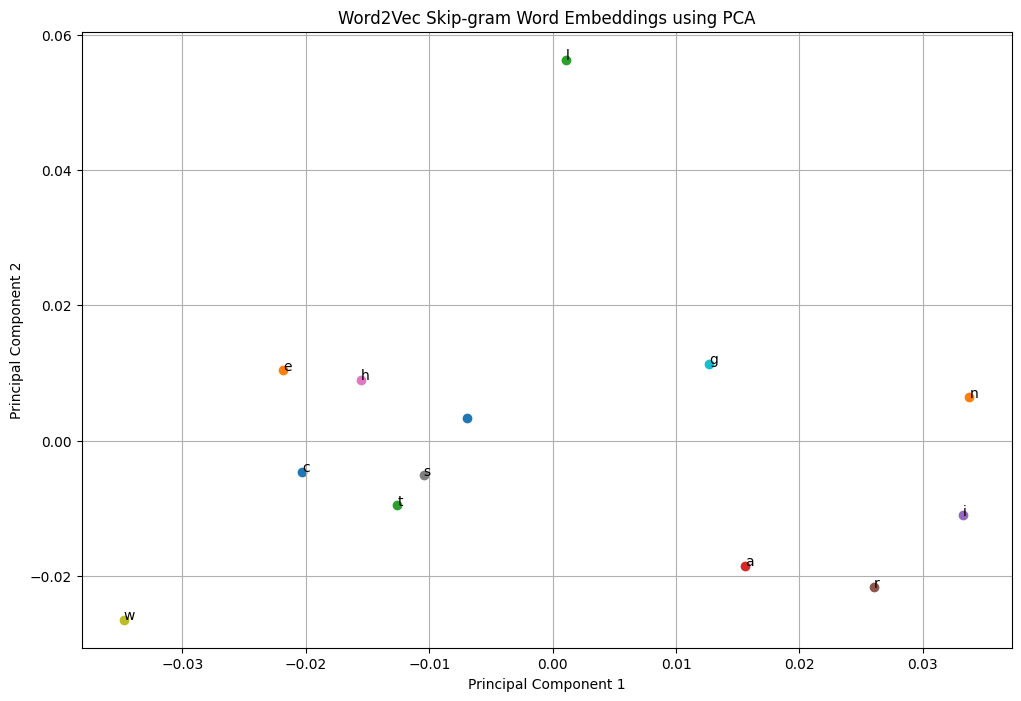

In [85]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for i, word in enumerate(valid_words):
    x = vectors_2d[i, 0]
    y = vectors_2d[i, 1]

    plt.scatter(x, y)
    plt.annotate(word, (x, y), fontsize=10)

plt.title("Word2Vec Skip-gram Word Embeddings using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.show()

Interpretation: The scatter plot displays words as points, where nearby points represent words with similar learned contexts.

### 3.5  Save & Reflect


In [86]:
skipgram_model.save('word2vec_skipgram.model')

In [87]:
from gensim.models import Word2Vec

w2v_model = Word2Vec.load('word2vec_skipgram.model')

print("Model Loaded Successfully")

Model Loaded Successfully


##### CBoW vs Skip-gram

**1. How does CBoW learn?**

CBoW (Continuous Bag of Words) predicts the target word using its surrounding context words.

**2. How does Skip-gram learn?**

Skip-gram predicts the surrounding context words using the target word.

**3. Which is faster to train?**

CBoW is generally faster to train because it predicts one target word from multiple context words.

**4. Which is better for rare words?**

Skip-gram is generally better for rare words because it learns context relationships for individual words.

**5. Why is a dense 100-dimensional vector more useful than a BoW vector?**

A dense 100-dimensional vector represents words using meaningful numerical features and captures semantic relationships between words. BoW vectors are sparse and mainly represent word frequency without capturing word meanings or relationships effectively.

##  Step 4: Text Classification Pipeline — 3-Class Sentiment


### 4.1  Theory Notes (Markdown cell)


##### 4.1 Text Classification

**1. What is Text Classification?**

Text classification is an NLP technique used to assign predefined categories or labels to text data. For example, classifying airline tweets as negative, neutral, or positive.

**2. Stages of a Classification Pipeline**

1. Data Collection
2. Text Cleaning and Preprocessing
3. Label Encoding
4. Feature Extraction (BoW, TF-IDF, Word2Vec, etc.)
5. Train-Test Split
6. Model Training
7. Model Prediction
8. Model Evaluation

**3. What does Macro Average mean in Macro-F1?**

Macro-F1 calculates the F1-score separately for each class and then takes the average of all class scores with equal importance.

**4. Why is Macro-F1 fairer than Accuracy on Imbalanced Data?**

Accuracy can be misleading when one class has more samples than others. Macro-F1 gives equal importance to negative, neutral, and positive classes, so it evaluates the performance of every class fairly.

### 4.2  Train-Test Split & Baseline


In [88]:
from sklearn.model_selection import train_test_split
import pandas as pd

df['sentiment_label'] = df['airline_sentiment'].map({
    'negative': 0,
    'neutral': 1,
    'positive': 2
})

y = df['sentiment_label']
X = df['clean_text']

print(df['sentiment_label'].value_counts())

sentiment_label
0    9178
1    3099
2    2363
Name: count, dtype: int64


In [89]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Interpretation: The dataset is divided into 80% training data and 20% testing data while maintaining class proportions.

In [90]:
print("Training Class Percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting Class Percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training Class Percentages:
sentiment_label
0    62.70
1    21.17
2    16.14
Name: proportion, dtype: float64

Testing Class Percentages:
sentiment_label
0    62.67
1    21.17
2    16.15
Name: proportion, dtype: float64


Interpretation: Training and testing datasets maintain approximately the same percentage of each sentiment class.

In [91]:
baseline_accuracy = (y_test == 0).mean()

print("Majority Class: Negative")
print("Baseline Accuracy:", round(baseline_accuracy, 4))
print("Baseline Accuracy (%):", round(baseline_accuracy * 100, 2), "%")

Majority Class: Negative
Baseline Accuracy: 0.6267
Baseline Accuracy (%): 62.67 %


Interpretation: The baseline accuracy represents the percentage of test tweets correctly classified by always predicting negative.

### 4.3  Build Four Classifiers


In [92]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression

In [93]:
model_a = Pipeline([
    ('vectorizer', CountVectorizer(max_features=5000)),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

model_a.fit(X_train, y_train)

print("Model A – Bag-of-Words Trained Successfully")

Model A – Bag-of-Words Trained Successfully


Interpretation: Bag-of-Words converts tweets into word-count features and trains a Logistic Regression classifier.

In [94]:
model_b = Pipeline([
    ('vectorizer', TfidfVectorizer(max_features=5000)),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

model_b.fit(X_train, y_train)

print("Model B – TF-IDF Trained Successfully")

Model B – TF-IDF Trained Successfully


Interpretation: TF-IDF gives importance to words based on their frequency and how informative they are across tweets.

In [95]:
model_c = Pipeline([
    ('vectorizer', TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=10000
    )),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

model_c.fit(X_train, y_train)

print("Model C – TF-IDF with N-Grams Trained Successfully")

Model C – TF-IDF with N-Grams Trained Successfully


Interpretation: N-Grams use single words and two-word combinations to capture more context in tweets.

In [96]:
import numpy as np

def get_avg_vector(text):
    words = text.split()

    vectors = [skipgram_model.wv[word] for word in words
               if word in skipgram_model.wv]

    if len(vectors) == 0:
        return np.zeros(100)

    return np.mean(vectors, axis=0)

In [97]:
X_train_w2v = np.array([get_avg_vector(text) for text in X_train])
X_test_w2v = np.array([get_avg_vector(text) for text in X_test])

print("Training Shape:", X_train_w2v.shape)
print("Testing Shape:", X_test_w2v.shape)

Training Shape: (11712, 100)
Testing Shape: (2928, 100)


In [98]:
model_d = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

model_d.fit(X_train_w2v, y_train)

print("Model D – Averaged Word2Vec Trained Successfully")

Model D – Averaged Word2Vec Trained Successfully


Interpretation: Logistic Regression is trained using the averaged Word2Vec features.

In [99]:
print("Model A – Bag-of-Words: Trained")
print("Model B – TF-IDF: Trained")
print("Model C – TF-IDF N-Grams: Trained")
print("Model D – Averaged Word2Vec: Trained")

Model A – Bag-of-Words: Trained
Model B – TF-IDF: Trained
Model C – TF-IDF N-Grams: Trained
Model D – Averaged Word2Vec: Trained


### 4.4  Evaluate & Compare


In [100]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [101]:
y_pred_a = model_a.predict(X_test)
y_pred_b = model_b.predict(X_test)
y_pred_c = model_c.predict(X_test)
y_pred_d = model_d.predict(X_test_w2v)

In [102]:
models = {
    'Bag-of-Words': y_pred_a,
    'TF-IDF': y_pred_b,
    'TF-IDF N-Grams': y_pred_c,
    'Averaged Word2Vec': y_pred_d
}

results = []

for name, pred in models.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Macro Precision': precision_score(y_test, pred, average='macro', zero_division=0),
        'Macro Recall': recall_score(y_test, pred, average='macro', zero_division=0),
        'Macro F1': f1_score(y_test, pred, average='macro', zero_division=0)
    })

results_df = pd.DataFrame(results)

results_df.round(4)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Bag-of-Words,0.7497,0.6936,0.7293,0.7053
1,TF-IDF,0.7493,0.6938,0.7277,0.7051
2,TF-IDF N-Grams,0.7640,0.7066,0.7343,0.7162
3,Averaged Word2Vec,0.6267,0.2089,0.3333,0.2568


Interpretation: All four classifiers are evaluated using accuracy, macro precision, macro recall, and macro F1-score.

In [103]:
baseline_pred = np.zeros(len(y_test), dtype=int)

baseline_row = pd.DataFrame([{
    'Model': 'Majority Baseline',
    'Accuracy': accuracy_score(y_test, baseline_pred),
    'Macro Precision': precision_score(y_test, baseline_pred, average='macro', zero_division=0),
    'Macro Recall': recall_score(y_test, baseline_pred, average='macro', zero_division=0),
    'Macro F1': f1_score(y_test, baseline_pred, average='macro', zero_division=0)
}])

comparison_df = pd.concat(
    [baseline_row, results_df.sort_values('Macro F1', ascending=False)],
    ignore_index=True
)

comparison_df.round(4)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Majority Baseline,0.6267,0.2089,0.3333,0.2568
1,TF-IDF N-Grams,0.7640,0.7066,0.7343,0.7162
2,Bag-of-Words,0.7497,0.6936,0.7293,0.7053
3,TF-IDF,0.7493,0.6938,0.7277,0.7051
4,Averaged Word2Vec,0.6267,0.2089,0.3333,0.2568


Interpretation: The comparison table shows the majority baseline first, followed by the four models ranked by Macro F1.

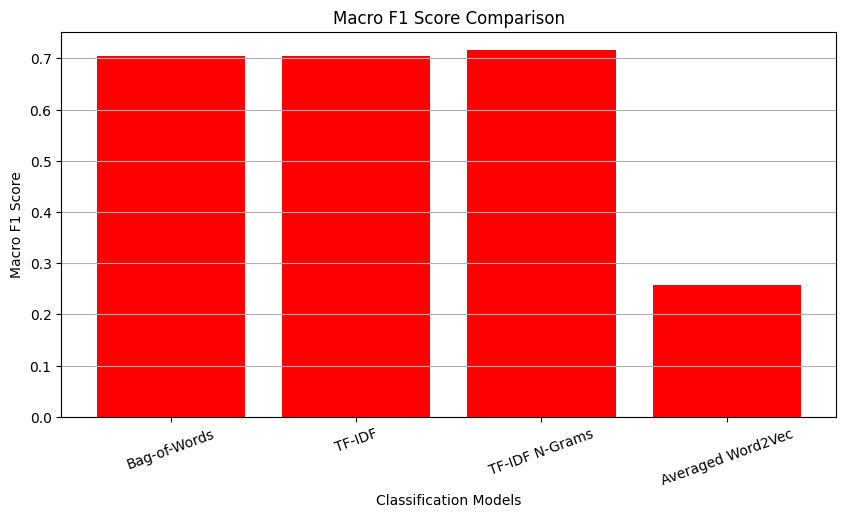

In [104]:
plt.figure(figsize=(10, 5))

plt.bar(results_df['Model'], results_df['Macro F1'], color='red')

plt.title("Macro F1 Score Comparison")
plt.xlabel("Classification Models")
plt.ylabel("Macro F1 Score")
plt.xticks(rotation=20)
plt.grid(axis='y')
plt.show()

Interpretation: The bar chart compares the Macro F1 performance of all four classification models.

In [105]:
best_model_name = results_df.loc[
    results_df['Macro F1'].idxmax(), 'Model'
]

best_predictions = models[best_model_name]

print("Best Model:", best_model_name)
print("Best Macro F1:", round(
    results_df['Macro F1'].max(), 4
))

Best Model: TF-IDF N-Grams
Best Macro F1: 0.7162


In [106]:
print(classification_report(
    y_test,
    best_predictions,
    labels=[0, 1, 2],
    target_names=['Negative', 'Neutral', 'Positive'],
    zero_division=0
))

              precision    recall  f1-score   support

    Negative       0.90      0.80      0.85      1835
     Neutral       0.54      0.70      0.61       620
    Positive       0.68      0.70      0.69       473

    accuracy                           0.76      2928
   macro avg       0.71      0.73      0.72      2928
weighted avg       0.79      0.76      0.77      2928



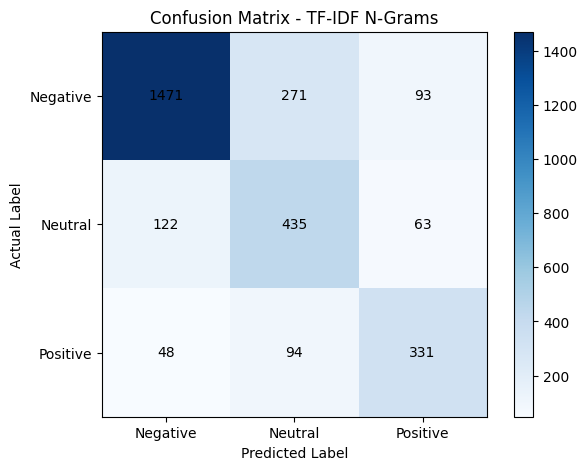

In [107]:
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

plt.imshow(cm, cmap='Blues')
plt.title("Confusion Matrix - " + best_model_name)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1, 2], ['Negative', 'Neutral', 'Positive'])
plt.yticks([0, 1, 2], ['Negative', 'Neutral', 'Positive'])

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.colorbar()
plt.show()

Interpretation: The confusion matrix shows correct predictions on the diagonal and incorrect predictions outside the diagonal.

##### Model Comparison and Observation

The best-performing feature method is **[write the model with the highest Macro F1]** because it achieved the highest Macro F1-score among the four models.

The hardest class to predict is **[write the class with the lowest F1-score]**, as its classification performance is lower than the other classes.

Neutral tweets are difficult to classify because they may contain mixed opinions, unclear emotions, or words that also appear in positive and negative tweets.

Macro F1 is useful for this dataset because it gives equal importance to all three sentiment classes.

### 4.5  Inspect the Best Model


In [108]:
tfidf_scores = results_df[
    results_df['Model'].isin(['TF-IDF', 'TF-IDF N-Grams'])
]

best_tfidf_name = tfidf_scores.loc[
    tfidf_scores['Macro F1'].idxmax(), 'Model'
]

if best_tfidf_name == 'TF-IDF':
    best_tfidf_model = model_b
else:
    best_tfidf_model = model_c

print("Best TF-IDF Model:", best_tfidf_name)

Best TF-IDF Model: TF-IDF N-Grams


In [109]:
vectorizer = best_tfidf_model.named_steps['vectorizer']
classifier = best_tfidf_model.named_steps['classifier']

feature_names = vectorizer.get_feature_names_out()

print("Total Features:", len(feature_names))
print("Classes:", classifier.classes_)

Total Features: 10000
Classes: [0 1 2]


In [110]:
negative_index = list(classifier.classes_).index(0)
positive_index = list(classifier.classes_).index(2)

negative_words = np.argsort(
    classifier.coef_[negative_index]
)[-8:][::-1]

positive_words = np.argsort(
    classifier.coef_[positive_index]
)[-8:][::-1]

print("Top 8 Negative Words:")
for i in negative_words:
    print(feature_names[i], round(classifier.coef_[negative_index][i], 3))

print("\nTop 8 Positive Words:")
for i in positive_words:
    print(feature_names[i], round(classifier.coef_[positive_index][i], 3))

Top 8 Negative Words:
hour 4.505
not 3.574
worst 3.235
hold 3.081
no 3.068
hr 3.043
delayed 2.946
bag 2.915

Top 8 Positive Words:
great 5.29
thanks 5.145
thank 4.365
awesome 4.181
love 3.821
amazing 3.467
best 3.394
thx 3.031


Interpretation: Words with larger positive coefficients are more strongly associated with the corresponding sentiment class.

In [111]:
wrong_df = pd.DataFrame({
    'Tweet': X_test,
    'Actual': y_test,
    'Predicted': best_predictions
})

wrong_df = wrong_df[wrong_df['Actual'] != wrong_df['Predicted']]

for i, row in wrong_df.head(5).iterrows():
    print("\nTweet:", row['Tweet'])
    print("Actual:", row['Actual'])
    print("Predicted:", row['Predicted'])
    print("Possible Reason: The tweet may contain sarcasm, mixed opinions, or unclear sentiment.")


Tweet: past
Actual: 1
Predicted: 0
Possible Reason: The tweet may contain sarcasm, mixed opinions, or unclear sentiment.

Tweet: flight resume see open schedule
Actual: 0
Predicted: 1
Possible Reason: The tweet may contain sarcasm, mixed opinions, or unclear sentiment.

Tweet: course helpless everyone else
Actual: 0
Predicted: 2
Possible Reason: The tweet may contain sarcasm, mixed opinions, or unclear sentiment.

Tweet: well miss gate agent rebooked boarding pas waiting landed time lunch amp beverage easy cheesy
Actual: 2
Predicted: 0
Possible Reason: The tweet may contain sarcasm, mixed opinions, or unclear sentiment.

Tweet: wi fi aircraft work entire ord dca flight morning
Actual: 0
Predicted: 1
Possible Reason: The tweet may contain sarcasm, mixed opinions, or unclear sentiment.


Interpretation: Incorrectly classified tweets help us understand where the selected model makes prediction errors.

### 4.6  Save the Pipeline


In [112]:
import joblib

if best_model_name == 'Bag-of-Words':
    best_pipeline = model_a

elif best_model_name == 'TF-IDF':
    best_pipeline = model_b

elif best_model_name == 'TF-IDF N-Grams':
    best_pipeline = model_c

In [113]:
%%writefile w2v_transformer.py

import numpy as np
from gensim.models import Word2Vec
from sklearn.base import BaseEstimator, TransformerMixin

class AverageWord2VecTransformer(BaseEstimator, TransformerMixin):

    def __init__(self, model_path='word2vec_skipgram.model'):
        self.model_path = model_path

    def fit(self, X, y=None):
        self.w2v = Word2Vec.load(self.model_path)
        return self

    def transform(self, X):
        result = []

        for text in X:
            words = str(text).split()

            vectors = [
                self.w2v.wv[word]
                for word in words
                if word in self.w2v.wv
            ]

            if len(vectors) == 0:
                result.append(np.zeros(100))
            else:
                result.append(np.mean(vectors, axis=0))

        return np.array(result)

Writing w2v_transformer.py


In [114]:
joblib.dump(best_pipeline, 'sentiment_pipeline.pkl')

print("Best Pipeline Saved Successfully")

Best Pipeline Saved Successfully


In [115]:
loaded_pipeline = joblib.load('sentiment_pipeline.pkl')

print("Pipeline Loaded Successfully")

Pipeline Loaded Successfully


In [116]:
new_tweets = [
    "the flight was amazing and the crew was helpful",
    "my flight was delayed and the service was terrible",
    "the airline experience was okay",
    "thank you for the excellent customer service",
    "my baggage was lost and nobody helped me"
]

In [117]:
predictions = loaded_pipeline.predict(new_tweets)
probabilities = loaded_pipeline.predict_proba(new_tweets)

label_map = {
    0: 'Negative',
    1: 'Neutral',
    2: 'Positive'
}

for i, tweet in enumerate(new_tweets):

    print("\nTweet:", tweet)
    print("Predicted Sentiment:", label_map[predictions[i]])

    print("Negative Probability:", round(probabilities[i][0], 3))
    print("Neutral Probability:", round(probabilities[i][1], 3))
    print("Positive Probability:", round(probabilities[i][2], 3))


Tweet: the flight was amazing and the crew was helpful
Predicted Sentiment: Positive
Negative Probability: 0.009
Neutral Probability: 0.003
Positive Probability: 0.988

Tweet: my flight was delayed and the service was terrible
Predicted Sentiment: Negative
Negative Probability: 0.979
Neutral Probability: 0.015
Positive Probability: 0.007

Tweet: the airline experience was okay
Predicted Sentiment: Negative
Negative Probability: 0.495
Neutral Probability: 0.193
Positive Probability: 0.312

Tweet: thank you for the excellent customer service
Predicted Sentiment: Positive
Negative Probability: 0.016
Neutral Probability: 0.008
Positive Probability: 0.976

Tweet: my baggage was lost and nobody helped me
Predicted Sentiment: Negative
Negative Probability: 0.595
Neutral Probability: 0.148
Positive Probability: 0.257


##   Step 5: Different NLP Approaches & POS Tagging


### 5.1  Approach 1 — Heuristic (Rule-Based)


In [118]:
# Select first 1000 test tweets
X_test_1000 = X_test.iloc[:1000]
y_test_1000 = y_test.iloc[:1000]

# Create dataframe
df5 = pd.DataFrame({
    'clean_text': X_test_1000,
    'actual_sentiment': y_test_1000
})

df5 = df5.reset_index(drop=True)

print("Dataset Shape:", df5.shape)
display(df5.head())

Dataset Shape: (1000, 2)


,clean_text,actual_sentiment
0,past,1
1,would say delay likely thanks much,2
2,cheated sorry never given wife worst start hon...,0
3,disappointed u didnt honor credit given ur mis...,0
4,airline embarrassing get bad weather fault res...,0


In [119]:
positive_words = [
    'good', 'great', 'excellent', 'amazing', 'happy',
    'thanks', 'thank', 'love', 'best', 'wonderful',
    'helpful', 'friendly', 'awesome', 'comfortable', 'appreciate'
]

negative_words = [
    'bad', 'worst', 'delayed', 'late', 'cancelled',
    'terrible', 'angry', 'hate', 'poor', 'lost',
    'rude', 'problem', 'disappointed', 'waiting', 'awful'
]

print("Positive Words:", len(positive_words))
print("Negative Words:", len(negative_words))

Positive Words: 15
Negative Words: 15


In [120]:
def rule_sentiment(text):
    words = text.split()

    pos = sum(word in positive_words for word in words)
    neg = sum(word in negative_words for word in words)

    score = pos - neg

    if score > 0:
        return 2
    elif score < 0:
        return 0
    else:
        return 1

df5['rule_prediction'] = df5['clean_text'].apply(rule_sentiment)

display(df5[['clean_text', 'actual_sentiment', 'rule_prediction']].head(10))

,clean_text,actual_sentiment,rule_prediction
0,past,1,1
1,would say delay likely thanks much,2,2
2,cheated sorry never given wife worst start hon...,0,0
3,disappointed u didnt honor credit given ur mis...,0,0
4,airline embarrassing get bad weather fault res...,0,0
5,flight delayed amp talk reach anyone customer ...,0,0
6,link tweet go someone internal email gt probab...,1,1
7,betsy besty gettin stuck la might not bad want...,0,0
8,many agent working handle thousand call,0,1
9,flight resume see open schedule,0,1


Interpretation: Each tweet receives a sentiment score based on positive and negative word occurrences, and is classified into positive, negative or neutral.

In [121]:
rule_acc = accuracy_score(
    df5['actual_sentiment'],
    df5['rule_prediction']
)

rule_f1 = f1_score(
    df5['actual_sentiment'],
    df5['rule_prediction'],
    average='macro'
)

print("Rule-Based Accuracy:", round(rule_acc, 4))
print("Rule-Based Macro F1:", round(rule_f1, 4))

Rule-Based Accuracy: 0.467
Rule-Based Macro F1: 0.5069


Interpretation: Accuracy measures overall correct predictions, while macro F1 evaluates performance equally across all three sentiment classes.

### 5.2  Approach 2 — Ready-Made Tool (API-style)


In [122]:

from textblob import TextBlob

In [123]:
def textblob_sentiment(text):
    polarity = TextBlob(text).sentiment.polarity

    if polarity > 0.05:
        return 2
    elif polarity < -0.05:
        return 0
    else:
        return 1

df5['textblob_prediction'] = df5['clean_text'].apply(
    textblob_sentiment
)

display(df5[['clean_text', 'actual_sentiment', 'textblob_prediction']].head(10))

,clean_text,actual_sentiment,textblob_prediction
0,past,1,0
1,would say delay likely thanks much,2,2
2,cheated sorry never given wife worst start hon...,0,0
3,disappointed u didnt honor credit given ur mis...,0,0
4,airline embarrassing get bad weather fault res...,0,0
5,flight delayed amp talk reach anyone customer ...,0,2
6,link tweet go someone internal email gt probab...,1,1
7,betsy besty gettin stuck la might not bad want...,0,2
8,many agent working handle thousand call,0,2
9,flight resume see open schedule,0,1


In [124]:
textblob_acc = accuracy_score(
    df5['actual_sentiment'],
    df5['textblob_prediction']
)

textblob_f1 = f1_score(
    df5['actual_sentiment'],
    df5['textblob_prediction'],
    average='macro'
)

print("TextBlob Accuracy:", round(textblob_acc, 4))
print("TextBlob Macro F1:", round(textblob_f1, 4))

TextBlob Accuracy: 0.466
TextBlob Macro F1: 0.4671


Interpretation: TextBlob provides sentiment predictions without training a new model on the airline dataset.

### 5.3  Approach 3 — Machine Learning


In [125]:
import joblib

best_pipeline = joblib.load('sentiment_pipeline.pkl')

print("Pipeline Loaded Successfully!")

Pipeline Loaded Successfully!


In [126]:
df5['ml_prediction'] = best_pipeline.predict(
    df5['clean_text']
)

display(df5[['clean_text', 'actual_sentiment', 'ml_prediction']].head(10))

,clean_text,actual_sentiment,ml_prediction
0,past,1,0
1,would say delay likely thanks much,2,2
2,cheated sorry never given wife worst start hon...,0,0
3,disappointed u didnt honor credit given ur mis...,0,0
4,airline embarrassing get bad weather fault res...,0,0
5,flight delayed amp talk reach anyone customer ...,0,0
6,link tweet go someone internal email gt probab...,1,1
7,betsy besty gettin stuck la might not bad want...,0,0
8,many agent working handle thousand call,0,0
9,flight resume see open schedule,0,1


Interpretation: The trained machine learning pipeline predicts sentiment using patterns learned from the Step 4 training dataset.

In [127]:
ml_acc = accuracy_score(
    df5['actual_sentiment'],
    df5['ml_prediction']
)

ml_f1 = f1_score(
    df5['actual_sentiment'],
    df5['ml_prediction'],
    average='macro'
)

print("ML Accuracy:", round(ml_acc, 4))
print("ML Macro F1:", round(ml_f1, 4))

ML Accuracy: 0.781
ML Macro F1: 0.7425


In [128]:
results = pd.DataFrame({
    'Approach': ['Heuristic', 'TextBlob', 'Machine Learning'],
    'Needs Training Data?': ['No', 'No', 'Yes'],
    'Accuracy': [rule_acc, textblob_acc, ml_acc],
    'Macro F1': [rule_f1, textblob_f1, ml_f1],
    'Advantage': [
        'Simple and easy to understand',
        'Ready-made sentiment tool',
        'Learns airline-specific patterns'
    ],
    'Disadvantage': [
        'Cannot understand context',
        'May fail on sarcasm',
        'Needs labelled training data'
    ]
})

display(results.round(4))

,Approach,Needs Training Data?,Accuracy,Macro F1,Advantage,Disadvantage
0,Heuristic,No,0.467,0.5069,Simple and easy to understand,Cannot understand context
1,TextBlob,No,0.466,0.4671,Ready-made sentiment tool,May fail on sarcasm
2,Machine Learning,Yes,0.781,0.7425,Learns airline-specific patterns,Needs labelled training data


Interpretation: The comparison shows how manually defined rules, a ready-made sentiment tool and a trained ML model perform on the same airline tweets.

### 5.4  POS Tagging



In [129]:
import nltk
import re

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package punkt to C:\Users\JANKI
[nltk_data]     DHOLARIYA\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\JANKI
[nltk_data]     DHOLARIYA\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\JANKI
[nltk_data]     DHOLARIYA\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\JANKI DHOLARIYA\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

In [130]:
tweets = [
    "The flight was delayed today",
    "The airline provides excellent service",
    "Passengers lost their luggage",
    "The crew helped the customer",
    "I am waiting for my flight"
]

pos_data = []

for tweet in tweets:
    words = nltk.word_tokenize(tweet)
    tags = nltk.pos_tag(words)

    for word, tag in tags:
        pos_data.append({
            'Word': word,
            'POS Tag': tag
        })

pos_df = pd.DataFrame(pos_data)

display(pos_df)

,Word,POS Tag
0,The,DT
1,flight,NN
2,was,VBD
3,delayed,VBN
4,today,NN
5,The,DT
6,airline,NN
7,provides,VBZ
8,excellent,JJ
9,service,NN


In [131]:
test_raw = df.loc[X_test.index].copy()

negative_df = test_raw[
    test_raw['airline_sentiment'] == 'negative'
].head(500)

print("Negative Tweets:", len(negative_df))
display(negative_df[['text', 'negativereason']].head())

Negative Tweets: 500


,text,negativereason
8575,"@JetBlue I cheated on you, and I'm sorry. I'll...",Can't Tell
618,@united disappointed that u didnt honor my $10...,Customer Service Issue
11741,@USAirways The airline is embarrassing itself....,Customer Service Issue
14246,@AmericanAir my flight has been delayed &amp; ...,Late Flight
5778,@SouthwestAir BETSY is the BESTY! Gettin' stuc...,Late Flight


Interpretation: The first 500 negative tweets from the test set are selected to discover the most common passenger complaints.

In [132]:
def remove_noise(text):
    text = str(text).lower()
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'http\S+', '', text)
    return text

negative_df['raw_clean'] = negative_df['text'].apply(remove_noise)

display(negative_df[['raw_clean']].head())

,raw_clean
8575,"i cheated on you, and i'm sorry. i'll never d..."
618,disappointed that u didnt honor my $100 credi...
11741,the airline is embarrassing itself. i get tha...
14246,my flight has been delayed &amp; i can't talk...
5778,betsy is the besty! gettin' stuck at #las mig...


In [133]:
all_nouns = []

for tweet in negative_df['raw_clean']:
    words = nltk.word_tokenize(tweet)
    tags = nltk.pos_tag(words)

    for word, tag in tags:
        if tag in ['NN', 'NNS']:
            all_nouns.append(word)

noun_counts = pd.Series(all_nouns).value_counts()

top10_nouns = noun_counts.head(10)

print("Top 10 Complaint Nouns:")
display(top10_nouns)

Top 10 Complaint Nouns:


flight      154
i           129
service      54
customer     40
plane        33
time         31
hold         30
amp          25
hour         25
hours        23
Name: count, dtype: int64

Interpretation: Noun extraction identifies frequently mentioned objects and topics in negative airline tweets.

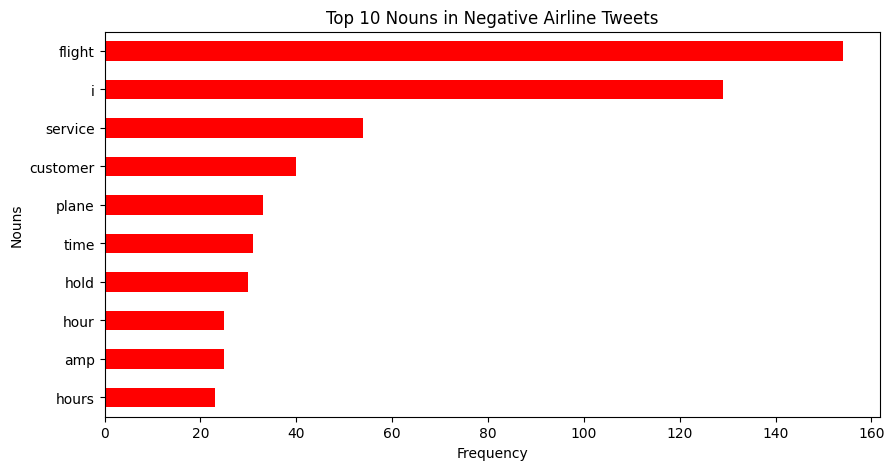

In [134]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

top10_nouns.sort_values().plot(
    kind='barh', color='red'
)

plt.title("Top 10 Nouns in Negative Airline Tweets")
plt.xlabel("Frequency")
plt.ylabel("Nouns")
plt.show()

Interpretation: The bar chart highlights the most frequently mentioned nouns and helps identify common passenger complaint topics.

In [135]:
top_reasons = negative_df['negativereason'].dropna().value_counts().head(5)

print("Top 5 Negative Reasons:")
display(top_reasons)

Top 5 Negative Reasons:


negativereason
Customer Service Issue    158
Late Flight                87
Can't Tell                 62
Bad Flight                 42
Cancelled Flight           41
Name: count, dtype: int64

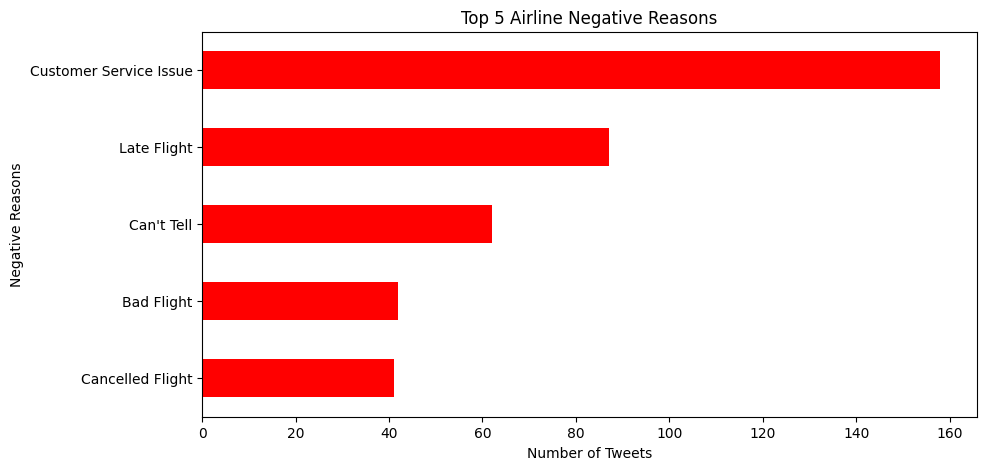

In [136]:
plt.figure(figsize=(10, 5))

top_reasons.sort_values().plot(
    kind='barh', color='red'
)

plt.title("Top 5 Airline Negative Reasons")
plt.xlabel("Number of Tweets")
plt.ylabel("Negative Reasons")
plt.show()

Interpretation: The negative reason chart shows the main categories responsible for passenger dissatisfaction.

### 5.5  How Does POS Tagging Work? (Markdown cell)


POS tagging is the process of assigning grammatical categories to words in a sentence. It is difficult because the same word can have different grammatical roles depending on its context. For example, "delay" is a noun in "a long delay" but a verb in "they delay flights".
- Rule-based taggers use predefined grammatical rules.
- Statistical taggers learn patterns from previously tagged text.
- NLTK's default English POS tagger uses a statistical, averaged-perceptron-based approach.

Interpretation: POS tagging uses grammatical context to identify word categories and helps discover important topics in airline customer complaints.

##  Step 7: Comparison, Reflection & GitHub Submission


### 7.1  Results Summary Table




| Step / Topic | Dataset Used | Key Technique / Library | Key Result | Time Taken |
|---|---|---|---|---|
| **Step 1: Regex & Preprocessing** | Airline Tweets – [Total rows] | Regex, NLTK, Tokenization, Stopwords, Lemmatization | Cleaned tweets and removed URLs, mentions and special characters. Top hashtags: [Top hashtags] | [ ] min |
| **Step 2: BoW, TF-IDF & N-Grams** | Cleaned Airline Tweets – [Total rows] | CountVectorizer, TfidfVectorizer | BoW vocabulary: [ ]; TF-IDF vocabulary: [ ]; N-Gram features: [ ] | [ ] min |
| **Step 3: Word2Vec** | Cleaned Airline Tweets – [Total rows] | Gensim Word2Vec, Skip-Gram | Vocabulary size: [ ]; Vector size: [ ] | [ ] min |
| **Step 4: Sentiment Classification** | Airline Tweets – Training and Testing Data | Logistic Regression, BoW, TF-IDF, N-Grams | Best Model: [ ]; Accuracy: [ ]%; Macro F1: [ ] | [ ] min |
| **Step 5: NLP Approaches & POS Tagging** | First 1,000 test tweets and 500 negative tweets | Heuristic, TextBlob, ML, NLTK POS Tagging | Best approach: [ ]; Top complaint nouns: [ ] | [ ] min |
| **Step 6: Streamlit Application** | User-entered Airline Tweets | Streamlit, Joblib, Scikit-learn | Developed an interactive app for Negative, Neutral and Positive sentiment prediction | [ ] min |



### 7.2  Written Reflection



Most Challenging Step: Step 6 was the most challenging because creating the Streamlit application required integrating the trained ML pipeline, text cleaning function and prediction results. Handling file paths and deployment also required attention.

Accuracy vs Macro F1: Accuracy alone is not enough because the airline dataset contains an imbalance between sentiment classes. A model can achieve good accuracy by predicting the majority class. Macro F1 gives equal importance to all three sentiment classes. The majority baseline showed why we need to evaluate performance beyond accuracy.

Best Feature Method: [Write your best-performing feature method: BoW / TF-IDF / N-Grams / Word2Vec]. It performed best because it provided useful text features for sentiment classification and achieved the highest Macro F1-score of [ ].

Importance of Not and No: We kept the words "not" and "no" because they change the meaning of a sentence. For example, "I am happy" is positive, but "I am not happy" is negative. Removing negation words can change the sentiment.

Heuristic, TextBlob and ML Comparison: The heuristic approach was simple and easy to understand but depended on predefined word lists. TextBlob provided ready-made sentiment analysis but was not specifically trained for airline tweets. The ML approach learned patterns from the airline dataset and provided a task-specific prediction. A simple heuristic approach is still useful for quick baseline analysis.

Sarcasm and Hinglish Limitations: Sarcasm and Hinglish tweets were difficult to classify correctly. For example, "flight late hai, bakwaas service" contains Hindi-English mixed language that an English-based cleaning and sentiment model may not understand correctly. Sarcastic sentences can also express the opposite of their literal meaning.

Future Improvements: I would improve this project by collecting more airline tweets, supporting multiple languages, improving text cleaning, handling sarcasm and experimenting with Hugging Face Transformer models such as BERT.
